# Práctica 4 — Ensambles sobre clasificadores bien ajustados
Introducción a la ciencia de datos  
Benjamín Hernández Herrera

**Pregunta.** ¿Cuánto ganan los ensambles sobre los cinco clasificadores base de la Práctica 3 cuando estos ya están bien ajustados?

**Parte 1 — Deserción estudiantil (Práctica 3).** Bagging (varianza), AdaBoost (sesgo), votación y *stacking* de los cinco base, Random Forest / Extra-Trees optimizados y dos bibliotecas de boosting optimizadas (XGBoost y LightGBM). Mismos cinco pliegues estratificados de la Práctica 3 (`random_state=42`).

**Parte 2 — Bank Marketing (Tarea 4).** Búsqueda del mejor modelo con `StratifiedKFold(5, shuffle=True, random_state=2026)`, sin la columna `duration`.

**Contenido**
0. Configuración, datos y clasificadores base recuperados de la Práctica 3
1. Varianza: árbol sin límite vs. bagging
2. Sesgo: tocón vs. AdaBoost
3. Combinar los cinco base: votación dura, votación suave y stacking
4. Random Forest y Extra-Trees optimizados
5. Boosting optimizado (XGBoost y LightGBM)
6. Tabla final de deserción y matriz de confusión del mejor modelo
7. Parte 2: Bank Marketing
8. Conclusiones

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 0. Configuración, datos y clasificadores base

In [2]:
import os, sys, time, platform, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy, sklearn
from scipy.stats import loguniform, randint, uniform

from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (OneHotEncoder, OrdinalEncoder, StandardScaler, KBinsDiscretizer,
                                   FunctionTransformer, LabelEncoder)
from sklearn.model_selection import (StratifiedKFold, RandomizedSearchCV, cross_validate,
                                      cross_val_predict, train_test_split)
from sklearn.metrics import (f1_score, recall_score, make_scorer, confusion_matrix, ConfusionMatrixDisplay)
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import CategoricalNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import (BaggingClassifier, AdaBoostClassifier, VotingClassifier, StackingClassifier,
                              RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier)
import joblib

try:
    from IPython.display import display
except ImportError:
    display = print
try:
    from sklearn.model_selection import TunedThresholdClassifierCV      # scikit-learn >= 1.5
except ImportError:
    TunedThresholdClassifierCV = None

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 60); pd.set_option("display.max_colwidth", 90)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})

# ---------------- Bibliotecas de boosting (se eligieron XGBoost y LightGBM) ----------------
# En Colab ya vienen instaladas; si no: !pip install -q xgboost lightgbm
try:
    from xgboost import XGBClassifier
except ImportError:
    XGBClassifier = None; print("xgboost no está instalado: !pip install -q xgboost")
try:
    from lightgbm import LGBMClassifier
except ImportError:
    LGBMClassifier = None; print("lightgbm no está instalado: !pip install -q lightgbm")

# ---------------- Configuración ----------------
SEED       = 42                                  # semilla de la Práctica 3 (deserción)
SEED_BANK  = 2026                                # semilla pedida para Bank Marketing
N_FOLDS    = 5
N_ITER     = int(os.environ.get("N_ITER", 60))   # configuraciones por búsqueda (>= 50)
N_ITER_BANK= int(os.environ.get("N_ITER_BANK", 50))
SEARCH_FRAC= float(os.environ.get("SEARCH_FRAC", 0.3))   # fracción de Bank Marketing usada para buscar hiperparámetros
BANK_N     = os.environ.get("BANK_N")            # solo para pruebas rápidas: nº de filas de Bank (None = todas)
CV_JOBS    = -1                                  # paralelismo entre pliegues
NOMBRE     = "benjamin-hernandez"                 # <-- cambia por el formato que pida la plataforma
DATA_DIR   = Path("/content/drive/MyDrive/dev")
OUT_DIR    = DATA_DIR / "salidas"; OUT_DIR.mkdir(exist_ok=True)
np.random.seed(SEED)
if N_ITER < 50 or N_ITER_BANK < 50:
    print("AVISO: la práctica exige al menos 50 configuraciones por búsqueda.")

print("Python:", sys.version.split()[0], "|", platform.platform())
libs = [np, pd, scipy, sklearn, joblib, __import__("matplotlib")]
for m in (XGBClassifier, LGBMClassifier):
    if m is not None: libs.append(sys.modules[m.__module__.split(".")[0]])
for lib in libs: print(f"{lib.__name__:<12}:", lib.__version__)
print("TunedThresholdClassifierCV disponible:", TunedThresholdClassifierCV is not None)

Python: 3.13.18 | Linux-6.6.159+-x86_64-with-glibc2.39
numpy       : 2.4.6
pandas      : 2.2.3
scipy       : 1.16.3
sklearn     : 1.6.1
joblib      : 1.6.0
matplotlib  : 3.10.0
xgboost     : 3.4.1
lightgbm    : 4.6.0
TunedThresholdClassifierCV disponible: True


In [3]:
# ---------------- Datos de deserción (Práctica 3) ----------------
train = pd.read_csv(DATA_DIR / "desercion-entrenamiento.csv")
train["Target"] = train["Target"].str.strip().str.lower()
test  = pd.read_csv(DATA_DIR / "desercion-prueba.csv")
FEATURES_1S = [c for c in train.columns if c in test.columns and c not in ("id", "Target")]
X, y = train[FEATURES_1S], train["Target"]
LABELS = sorted(y.unique())
print(X.shape, y.value_counts().to_dict())

NOMINAL = ["Marital status", "Application mode", "Course", "Previous qualification", "Nacionality",
           "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation"]
BINARY  = ["Daytime/evening attendance", "Displaced", "Educational special needs", "Debtor",
           "Tuition fees up to date", "Gender", "Scholarship holder", "International"]
def sel_nominal(df): return [c for c in NOMINAL if c in df.columns]
def sel_binary(df):  return [c for c in BINARY  if c in df.columns]
def sel_numeric(df): return [c for c in df.columns if c not in NOMINAL + BINARY]

cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)   # los mismos 5 pliegues de la Práctica 3

def make_ohe(min_freq=0.01):
    return OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=min_freq, sparse_output=False)

def make_prep(scale, min_freq=0.01):
    return ColumnTransformer([("nom", make_ohe(min_freq), sel_nominal),
                              ("bin", "passthrough", sel_binary),
                              ("num", StandardScaler() if scale else "passthrough", sel_numeric)])

def plus_one(a): return a + 1

def make_prep_categorical_nb(n_bins=4, strategy="quantile"):
    return ColumnTransformer([
        ("nom", Pipeline([("ord", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)),
                          ("shift", FunctionTransformer(plus_one))]), sel_nominal),
        ("bin", "passthrough", sel_binary),
        ("num", KBinsDiscretizer(n_bins=n_bins, encode="ordinal", strategy=strategy), sel_numeric)])

(3539, 30) {'graduate': 1767, 'dropout': 1137, 'enrolled': 635}


### Clasificadores base recuperados de la Práctica 3

Se reconstruyen con **el mismo preprocesamiento y los mejores hiperparámetros** de la Práctica 3 (sin repetir la optimización). Para comprobar que la reconstrucción es fiel, se reevalúa cada uno con los mismos pliegues y se compara con el F1 macro que se obtuvo entonces.

| Clasificador | Hiperparámetros ganadores (Práctica 3) | F1 macro en la Práctica 3 |
|---|---|---|
| Árbol | `entropy`, `max_depth=6`, `min_samples_leaf=29`, `ccp_alpha≈5.0e-4`, `class_weight="balanced"`, one-hot con `min_frequency=0.03` | 0.644 ± 0.015 |
| Naive Bayes | `CategoricalNB`, `alpha≈2.51`, `fit_prior=False`, 4 bins por cuantiles | 0.625 ± 0.014 |
| kNN | `k=5`, `weights="distance"`, distancia euclidiana, `min_frequency=0.03` | 0.560 ± 0.027 |
| SVM | RBF, `C≈1.63`, `gamma≈0.0229`, `class_weight="balanced"`, `min_frequency=0.005` | 0.676 ± 0.008 |
| Regresión logística | elastic net (`l1_ratio=0.7`), `C≈0.137`, `class_weight="balanced"`, `min_frequency=0.005` | 0.679 ± 0.011 |

In [4]:
NEW_LR_API = LogisticRegression().get_params().get("penalty", "deprecated") == "deprecated"

def base_pipelines(calibrate_svm=False):
    lr_kw = dict(solver="saga", C=0.137310924682403, class_weight="balanced", max_iter=1000, tol=1e-3, random_state=SEED)
    lr_kw.update({"l1_ratio": 0.7} if NEW_LR_API else {"penalty": "elasticnet", "l1_ratio": 0.7})
    svm = Pipeline([("prep", make_prep(True, 0.005)),
                    ("clf", SVC(kernel="rbf", C=1.6315698516262178, gamma=0.022881441989554118,
                                class_weight="balanced", random_state=SEED))])
    return {
        "Árbol": Pipeline([("prep", make_prep(False, 0.03)),
                           ("clf", DecisionTreeClassifier(criterion="entropy", max_depth=6, min_samples_leaf=29,
                                                          ccp_alpha=0.0005019072833961318, class_weight="balanced",
                                                          random_state=SEED))]),
        "Naive Bayes": Pipeline([("prep", make_prep_categorical_nb(4, "quantile")),
                                 ("clf", CategoricalNB(alpha=2.512779099948728, fit_prior=False))]),
        "kNN": Pipeline([("prep", make_prep(True, 0.03)),
                         ("clf", KNeighborsClassifier(n_neighbors=5, weights="distance", metric="euclidean"))]),
        "SVM": CalibratedClassifierCV(svm, method="sigmoid", cv=3) if calibrate_svm else svm,
        "Regresión logística": Pipeline([("prep", make_prep(True, 0.005)), ("clf", LogisticRegression(**lr_kw))]),
    }
BASE = base_pipelines()

In [5]:
# ---------------- Evaluación uniforme: cross_validate con los mismos pliegues ----------------
SCORING_DES = {"f1_macro": "f1_macro",
               "sens_enrolled": make_scorer(recall_score, labels=["enrolled"], average="macro", zero_division=0)}
ROWS_DES = []        # filas de la tabla final de deserción

def evaluate(name, model, X_, y_, cv_, scoring, sens_col, rows, search_time=np.nan, config="", family=""):
    res = cross_validate(clone(model), X_, y_, cv=cv_, scoring=scoring, n_jobs=CV_JOBS)
    row = {"modelo": name, "familia": family, "F1 macro (media)": res["test_f1_macro"].mean(),
           "F1 macro (desv.)": res["test_f1_macro"].std(ddof=0),
           sens_col: res[f"test_{sens_col}"].mean(),
           "t. entrenamiento por pliegue (s)": res["fit_time"].mean(),
           "t. búsqueda (s)": search_time, "configuración": config}
    rows.append(row)
    print(f"{name:<44} F1 macro = {row['F1 macro (media)']:.4f} ± {row['F1 macro (desv.)']:.4f} | "
          f"{sens_col} = {row[sens_col]:.3f} | fit/pliegue = {row['t. entrenamiento por pliegue (s)']:.1f} s")
    return res

# Verificación de la reconstrucción: debe reproducir los F1 macro de la Práctica 3
for name, est in BASE.items():
    evaluate(name, est, X, y, cv, SCORING_DES, "sens_enrolled", ROWS_DES, family="base (Práctica 3)")

Árbol                                        F1 macro = 0.6439 ± 0.0154 | sens_enrolled = 0.570 | fit/pliegue = 0.1 s
Naive Bayes                                  F1 macro = 0.6249 ± 0.0139 | sens_enrolled = 0.487 | fit/pliegue = 0.1 s
kNN                                          F1 macro = 0.5596 ± 0.0268 | sens_enrolled = 0.217 | fit/pliegue = 0.0 s
SVM                                          F1 macro = 0.6757 ± 0.0084 | sens_enrolled = 0.578 | fit/pliegue = 1.3 s
Regresión logística                          F1 macro = 0.6792 ± 0.0106 | sens_enrolled = 0.575 | fit/pliegue = 2.1 s


## 1. Varianza: árbol sin límite de profundidad vs. bagging

Un árbol sin límite de profundidad (profundidad ilimitada, sin poda, hojas de 1 muestra) tiene sesgo bajo pero varianza alta. **Bagging** promedia muchos de esos árboles entrenados con remuestreos bootstrap. Se evalúan cantidades crecientes de árboles (1, 5, 10, 20, 50, 100, 200, 300 y 400) agregando árboles progresivamente con `warm_start=True`.

Para mantener la fidelidad con la Práctica 3, ambos usan el mismo preprocesamiento del árbol (one-hot con `min_frequency=0.03`, ajustado solo con el pliegue de entrenamiento) y `class_weight="balanced"`; así lo único que cambia es la profundidad y el promedio de árboles.

In [6]:
SIZES = [1, 5, 10, 20, 50, 100, 200, 300, 400]
REC_ENR = lambda yt, yp: recall_score(yt, yp, labels=["enrolled"], average="macro", zero_division=0)

def tree_unlimited():
    return DecisionTreeClassifier(criterion="entropy", max_depth=None, min_samples_leaf=1, ccp_alpha=0.0,
                                  class_weight="balanced", random_state=SEED)

# Árbol sin límite de profundidad (mismo preprocesamiento del árbol de la Práctica 3)
pipe_tree_full = Pipeline([("prep", make_prep(False, 0.03)), ("clf", tree_unlimited())])
res_tree_full = evaluate("Árbol sin límite de profundidad", pipe_tree_full, X, y, cv, SCORING_DES,
                         "sens_enrolled", ROWS_DES, family="varianza")

def curve_bagging(sizes=SIZES):
    out = []
    for k, (tr, te) in enumerate(cv.split(X, y)):
        prep = make_prep(False, 0.03).fit(X.iloc[tr])
        Xtr, Xte = prep.transform(X.iloc[tr]), prep.transform(X.iloc[te])
        bag = BaggingClassifier(estimator=tree_unlimited(), n_estimators=1, warm_start=True, bootstrap=True,
                                random_state=SEED, n_jobs=1)
        t_acc = 0.0
        for n in sizes:
            t0 = time.perf_counter(); bag.set_params(n_estimators=n); bag.fit(Xtr, y.iloc[tr]); t_acc += time.perf_counter() - t0
            p = bag.predict(Xte)
            out.append({"pliegue": k, "n": n, "f1": f1_score(y.iloc[te], p, average="macro"),
                        "sens_enrolled": REC_ENR(y.iloc[te], p), "t_acum": t_acc})
    return pd.DataFrame(out)

curve_bag = curve_bagging()
g = curve_bag.groupby("n")
bag_curve = pd.DataFrame({"f1_media": g["f1"].mean(), "f1_desv": g["f1"].std(ddof=0)})
display(bag_curve.round(4))

Árbol sin límite de profundidad              F1 macro = 0.5911 ± 0.0269 | sens_enrolled = 0.373 | fit/pliegue = 0.1 s


,f1_media,f1_desv
n,,
1,0.5783,0.0191
5,0.6218,0.0093
10,0.6267,0.0091
20,0.6495,0.0149
50,0.6605,0.0198
100,0.6638,0.0220
200,0.6586,0.0205
300,0.6596,0.0194
400,0.6603,0.0222


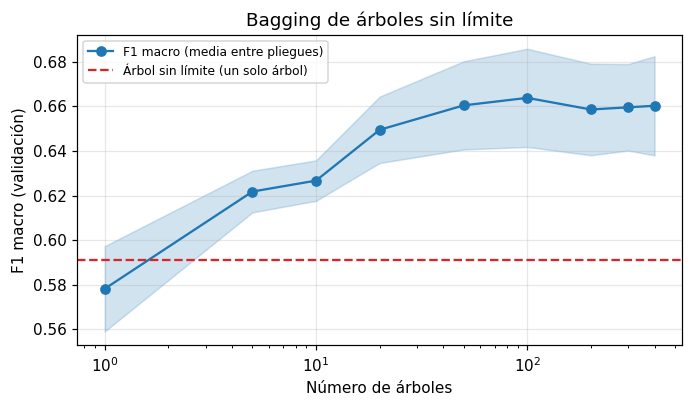

Bagging (400 árboles sin límite) F1 macro = 0.6603 ± 0.0222


In [7]:
def plot_curve(curve, ref=None, ref_label="", title="", xlabel="Número de árboles", fname="curva.png", logx=True):
    fig, ax = plt.subplots(figsize=(6.4, 3.8))
    ax.plot(curve.index, curve["f1_media"], marker="o", color="C0", label="F1 macro (media entre pliegues)")
    ax.fill_between(curve.index, curve["f1_media"] - curve["f1_desv"], curve["f1_media"] + curve["f1_desv"], alpha=.2, color="C0")
    if ref is not None: ax.axhline(ref, color="C3", ls="--", label=ref_label)
    if logx: ax.set_xscale("log")
    ax.set_xlabel(xlabel); ax.set_ylabel("F1 macro (validación)"); ax.set_title(title); ax.legend(fontsize=8)
    fig.tight_layout(); fig.savefig(OUT_DIR / fname); plt.show()

plot_curve(bag_curve, ref=res_tree_full["test_f1_macro"].mean(), ref_label="Árbol sin límite (un solo árbol)",
           title="Bagging de árboles sin límite", fname="curva_bagging.png")

last = curve_bag[curve_bag.n == SIZES[-1]]
ROWS_DES.append({"modelo": f"Bagging ({SIZES[-1]} árboles sin límite)", "familia": "varianza",
                 "F1 macro (media)": last.f1.mean(), "F1 macro (desv.)": last.f1.std(ddof=0),
                 "sens_enrolled": last.sens_enrolled.mean(), "t. entrenamiento por pliegue (s)": last.t_acum.mean(),
                 "t. búsqueda (s)": np.nan, "configuración": f"n_estimators={SIZES[-1]}, bootstrap, warm_start"})
print(ROWS_DES[-1]["modelo"], f"F1 macro = {last.f1.mean():.4f} ± {last.f1.std(ddof=0):.4f}")

### ¿Qué reduce bagging, y por qué?

- **Cuánto mejora.** El árbol sin límite de profundidad obtiene un F1 macro de 0.591 ± 0.027 y el bagging de 400 árboles, 0.660 ± 0.022: **+0.069**. Un solo árbol bootstrap (n = 1) queda en 0.578, igual o algo peor que el árbol original porque cada árbol ve solo ~63 % de los estudiantes distintos. La curva sube rápido hasta ≈ 50 árboles (0.661) y desde ahí se aplana (0.659–0.664 entre 100 y 400): agregar árboles no mejora más, pero tampoco empeora.
- **Qué reduce: la varianza.** Un árbol sin límite memoriza el entrenamiento (sesgo bajo, varianza alta): su predicción cambia mucho si cambian algunos estudiantes de la muestra. Cada árbol del bagging se entrena con una muestra bootstrap distinta, así que sus errores "aleatorios" son distintos y se compensan al votar. El sesgo casi no cambia, porque cada árbol sigue siendo igual de flexible; por eso la ganancia aparece sin tocar la profundidad.
- **Por qué se aplana.** Los árboles no son independientes (se entrenan con datos muy parecidos y miran los mismos atributos), de modo que sus errores están correlacionados y la varianza del promedio tiene un piso. Pasado ese punto, más árboles solo estabilizan la predicción; no hay riesgo de sobreajuste por añadir árboles.
- **Matiz sobre la desviación entre pliegues.** No bajó de forma clara (0.027 → 0.022): esa desviación depende sobre todo de qué estudiantes caen en cada pliegue de validación, no de la varianza del modelo. La reducción de varianza se ve en la media del F1, no en la dispersión entre pliegues.
- **Límites.** El bagging (0.660) sigue por debajo de la regresión logística (0.679) y del SVM (0.676) de la Práctica 3, y su sensibilidad de `enrolled` es de apenas 0.34 (el árbol podado de la Práctica 3 tenía 0.57). Promediar árboles profundos reduce varianza, pero no corrige que el modelo no capture bien una clase intermedia y minoritaria.

## 2. Sesgo: tocón vs. AdaBoost

Un **tocón** (árbol de profundidad 1) tiene sesgo alto y varianza baja. **AdaBoost** entrena tocones en secuencia, dando más peso a los ejemplos mal clasificados en cada ronda. Se obtiene el F1 macro después de cada ronda (hasta 400) con `staged_predict()`. Mismo preprocesamiento que el árbol. **Nota:** el tocón va **sin** `class_weight`: con `class_weight="balanced"` el tocón no supera al azar (error ≥ 2/3 con 3 clases) tras la primera reponderación y AdaBoost se detiene después de ~3 rondas (F1 macro ≈ 0.49); AdaBoost ya reajusta los pesos de las muestras por sí mismo.

Tocón (profundidad 1)                        F1 macro = 0.4920 ± 0.0121 | sens_enrolled = 0.000 | fit/pliegue = 0.0 s
Mejor ronda (media entre pliegues): 270 con F1 macro = 0.6460


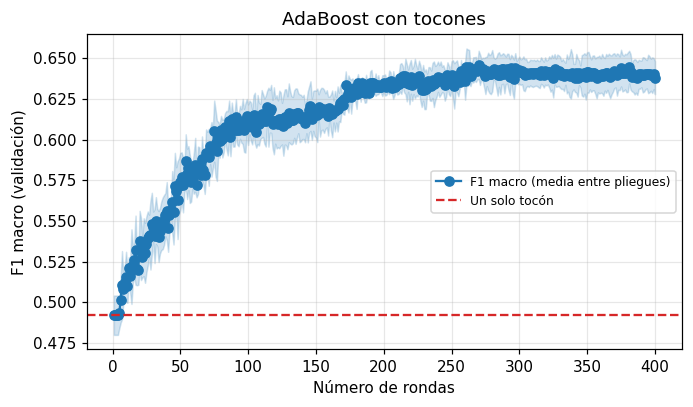

AdaBoost (400 rondas, tocones) F1 macro = 0.6381 ± 0.0102


In [8]:
N_ROUNDS = 400
def stump(): return DecisionTreeClassifier(max_depth=1, random_state=SEED)   # sin class_weight (ver nota)

pipe_stump = Pipeline([("prep", make_prep(False, 0.03)), ("clf", stump())])
res_stump = evaluate("Tocón (profundidad 1)", pipe_stump, X, y, cv, SCORING_DES, "sens_enrolled", ROWS_DES, family="sesgo")

def curve_adaboost(rounds=N_ROUNDS):
    out = []
    for k, (tr, te) in enumerate(cv.split(X, y)):
        prep = make_prep(False, 0.03).fit(X.iloc[tr])
        Xtr, Xte = prep.transform(X.iloc[tr]), prep.transform(X.iloc[te])
        ada = AdaBoostClassifier(estimator=stump(), n_estimators=rounds, random_state=SEED)
        t0 = time.perf_counter(); ada.fit(Xtr, y.iloc[tr]); t_fit = time.perf_counter() - t0
        for r, p in enumerate(ada.staged_predict(Xte), start=1):
            out.append({"pliegue": k, "n": r, "f1": f1_score(y.iloc[te], p, average="macro"),
                        "sens_enrolled": REC_ENR(y.iloc[te], p), "t_fit": t_fit})
    return pd.DataFrame(out)

curve_ada = curve_adaboost()
g = curve_ada.groupby("n")
ada_curve = pd.DataFrame({"f1_media": g["f1"].mean(), "f1_desv": g["f1"].std(ddof=0)})
print("Mejor ronda (media entre pliegues):", int(ada_curve["f1_media"].idxmax()),
      f"con F1 macro = {ada_curve['f1_media'].max():.4f}")
plot_curve(ada_curve, ref=res_stump["test_f1_macro"].mean(), ref_label="Un solo tocón",
           title="AdaBoost con tocones", xlabel="Número de rondas", fname="curva_adaboost.png", logx=False)

last = curve_ada[curve_ada.n == N_ROUNDS]
ROWS_DES.append({"modelo": f"AdaBoost ({N_ROUNDS} rondas, tocones)", "familia": "sesgo",
                 "F1 macro (media)": last.f1.mean(), "F1 macro (desv.)": last.f1.std(ddof=0),
                 "sens_enrolled": last.sens_enrolled.mean(), "t. entrenamiento por pliegue (s)": last.t_fit.mean(),
                 "t. búsqueda (s)": np.nan, "configuración": f"n_estimators={N_ROUNDS}, learning_rate=1.0"})
print(ROWS_DES[-1]["modelo"], f"F1 macro = {last.f1.mean():.4f} ± {last.f1.std(ddof=0):.4f}")

### ¿Qué reduce boosting, y por qué?

- **Cuánto mejora.** El tocón obtiene 0.492 (nunca predice `enrolled`: sensibilidad 0) y AdaBoost de 400 rondas, 0.638 ± 0.010: **+0.146**. La curva sube con rapidez durante las primeras ~100 rondas (≈ 0.61), sigue subiendo más despacio hasta ≈ 200 (≈ 0.63) y se aplana en ≈ 0.64 desde la ronda ≈ 270 (máximo 0.646 en la ronda 270). No hay señal de sobreajuste en 400 rondas: la curva no baja, solo se estabiliza.
- **Qué reduce: el sesgo.** Un tocón es demasiado simple para este problema (subajusta): una sola pregunta sobre un atributo no puede separar tres clases. AdaBoost construye un modelo aditivo; cada nuevo tocón se concentra en los estudiantes que los anteriores clasifican mal (les sube el peso), y la combinación ponderada puede representar fronteras mucho más complejas que cualquier tocón. Cada aprendiz tiene varianza baja, por lo que el costo en varianza es moderado.
- **Contraste con bagging.** Bagging parte de aprendices de sesgo bajo y varianza alta y los promedia (reduce varianza); boosting parte de aprendices de sesgo alto y varianza baja y los suma secuencialmente (reduce sesgo). En ambos casos la mejora respecto al aprendiz individual es grande (+0.069 y +0.146), pero **ninguno alcanza a la regresión logística** (0.679): bagging termina en 0.660 y AdaBoost en 0.638. Eso sugiere que en deserción el límite no está en que falte flexibilidad ni en que sobre varianza, sino en la información disponible al cierre del primer semestre (ver el análisis de errores comunes, sección 3).
- **Sensibilidad de `enrolled`.** AdaBoost solo llega a 0.27: sin pesos por clase (con `class_weight="balanced"` el tocón no supera al azar y AdaBoost se detiene), el algoritmo privilegia a las clases grandes.

## 3. Combinar los cinco clasificadores base

- **Votación dura:** cada clasificador vota por una clase y gana la mayoría.
- **Votación suave:** se promedian las probabilidades. Requiere probabilidades; las del SVM salen de `CalibratedClassifierCV` (calibración sigmoide con 3 pliegues internos). Como la calibración es parte del estimador, **se ajusta dentro de cada partición de entrenamiento** de la validación cruzada externa, sin ver el pliegue de validación.
- **Stacking:** las probabilidades de los cinco base (obtenidas con validación cruzada interna de 5 pliegues) alimentan un meta-modelo de regresión logística. Se evalúa con `cross_validate` y los mismos cinco pliegues externos.

La votación dura usa el SVM sin calibrar (no necesita probabilidades).

In [9]:
inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
def estimators(calibrated):
    return list(base_pipelines(calibrate_svm=calibrated).items())

vote_hard = VotingClassifier(estimators(False), voting="hard", n_jobs=1)
vote_soft = VotingClassifier(estimators(True),  voting="soft", n_jobs=1)
stack = StackingClassifier(estimators(True),
                           final_estimator=LogisticRegression(C=1.0, class_weight="balanced", max_iter=2000),
                           cv=inner_cv, stack_method="predict_proba", n_jobs=1)

evaluate("Votación dura (5 base)",  vote_hard, X, y, cv, SCORING_DES, "sens_enrolled", ROWS_DES, family="combinar base")
evaluate("Votación suave (5 base)", vote_soft, X, y, cv, SCORING_DES, "sens_enrolled", ROWS_DES, family="combinar base")
evaluate("Stacking (meta: reg. logística)", stack, X, y, cv, SCORING_DES, "sens_enrolled", ROWS_DES, family="combinar base")

Votación dura (5 base)                       F1 macro = 0.6808 ± 0.0129 | sens_enrolled = 0.542 | fit/pliegue = 3.2 s
Votación suave (5 base)                      F1 macro = 0.6775 ± 0.0109 | sens_enrolled = 0.452 | fit/pliegue = 4.3 s
Stacking (meta: reg. logística)              F1 macro = 0.6866 ± 0.0080 | sens_enrolled = 0.617 | fit/pliegue = 24.7 s


{'fit_time': array([25.73572469, 27.96913958, 27.50321054, 28.24178576, 13.91979146]),
 'score_time': array([0.70674467, 0.74179864, 0.72113514, 0.75876403, 0.39782143]),
 'test_f1_macro': array([0.68182086, 0.6760836 , 0.70006679, 0.6883014 , 0.68685955]),
 'test_sens_enrolled': array([0.66929134, 0.62992126, 0.58267717, 0.59055118, 0.61417323])}

,Árbol,Naive Bayes,kNN,SVM,Regresión logística
Árbol,1.000,0.477,0.380,0.611,0.593
Naive Bayes,0.477,1.000,0.388,0.565,0.564
kNN,0.380,0.388,1.000,0.455,0.399
SVM,0.611,0.565,0.455,1.000,0.762
Regresión logística,0.593,0.564,0.399,0.762,1.000


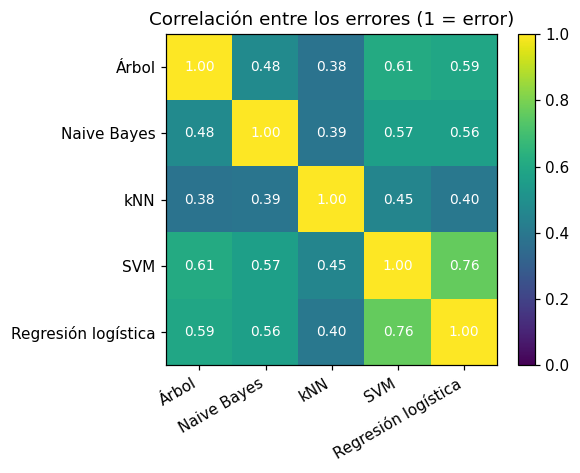

Correlación media entre pares: 0.520 (mín 0.380, máx 0.762)
Estudiantes mal clasificados por k de los 5 modelos (proporción):
0    0.449
1    0.169
2    0.092
3    0.079
4    0.094
5    0.117


In [10]:
# ¿Qué tan correlacionados están los errores de los cinco clasificadores?
oof = {n: cross_val_predict(clone(m), X, y, cv=cv, n_jobs=CV_JOBS) for n, m in BASE.items()}
errors = pd.DataFrame({n: (p != y.to_numpy()).astype(int) for n, p in oof.items()})
corr = errors.corr()
display(corr.round(3))

fig, ax = plt.subplots(figsize=(5.4, 4.4))
im = ax.imshow(corr.values, vmin=0, vmax=1, cmap="viridis")
ax.set_xticks(range(5)); ax.set_xticklabels(corr.columns, rotation=30, ha="right"); ax.set_yticks(range(5)); ax.set_yticklabels(corr.columns)
for i in range(5):
    for j in range(5): ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", color="w", fontsize=9)
ax.grid(False); fig.colorbar(im, fraction=.046); ax.set_title("Correlación entre los errores (1 = error)")
fig.tight_layout(); fig.savefig(OUT_DIR / "correlacion_errores.png"); plt.show()

off = corr.values[np.triu_indices(5, k=1)]
print(f"Correlación media entre pares: {off.mean():.3f} (mín {off.min():.3f}, máx {off.max():.3f})")
n_wrong = errors.sum(axis=1)
print("Estudiantes mal clasificados por k de los 5 modelos (proporción):")
print(n_wrong.value_counts(normalize=True).sort_index().round(3).to_string())

### Errores correlacionados e implicaciones

- **Correlación.** La correlación media entre pares de errores es **0.52** (mínimo 0.38, máximo 0.76). Los más parecidos son la **regresión logística y el SVM (0.76)**: ambos usan el mismo preprocesamiento (one-hot y estandarización) y una frontera casi lineal, así que se equivocan en los mismos estudiantes. Árbol–SVM (0.61), árbol–regresión logística (0.59) y Naive Bayes–SVM/regresión logística (≈ 0.56–0.57) también son altas. **kNN es el más distinto** (0.38–0.45 con todos), pero es también el peor clasificador (0.560).
- **Qué implica.** Un ensamble solo ayuda si los miembros fallan en estudiantes distintos. Aquí hay mucha coincidencia, y el desglose lo confirma: **el 44.9 %** de los estudiantes lo acierta cada uno de los cinco modelos y el **11.7 %** lo falla cada uno de los cinco; solo 16.9 % tiene exactamente un error. Ese 11.7 % es un piso para cualquier combinación de estos modelos: no hay votación ni stacking que los corrija, porque ningún miembro los acierta. Coincide con lo visto en la Práctica 3: desertores que al cierre del primer semestre se parecen a graduados o inscritos.
- **Por qué las combinaciones aportan poco.** La votación suave (0.678) no supera a la regresión logística (0.679) y la votación dura (0.681) tampoco por más que la desviación entre pliegues (≈ 0.01). El **stacking** (0.687 ± 0.008) sí queda arriba, pero por solo +0.008 sobre el mejor base y su sensibilidad de `enrolled` es mejor (0.617 frente a 0.575), a costa de ser ≈ 12 veces más lento (24.7 s por pliegue frente a 2.1 s). Poca diversidad (varios miembros casi lineales y correlacionados) y un miembro mucho peor (kNN) limitan lo que se puede ganar; el meta-modelo puede aprender a darle poco peso a kNN, lo que explica por qué el stacking sí mejora un poco y el voto simple no.

## 4. Bagging optimizado: Random Forest y Extra-Trees

`RandomizedSearchCV` con F1 macro y **los mismos cinco pliegues**, **N_ITER configuraciones** (≥ 50) por modelo, `random_state` fijo. El preprocesamiento es el del árbol (one-hot, numéricos sin escalar). Cada búsqueda usa 200 árboles por configuración para acotar el tiempo.

Espacio de búsqueda: `max_features` (sqrt, log2, o una fracción 0.2–0.7), `max_depth` (None o 5–20), `min_samples_leaf` (1–30), `criterion` (gini, entropy, log_loss), `class_weight` (None, balanced, balanced_subsample), `min_frequency` del one-hot y, en Extra-Trees, además `bootstrap` (True/False).

[Random Forest] configuraciones evaluadas: 60 (fallidas: 0) | tiempo de búsqueda: 395.3 s | mejor f1_macro: 0.6805
      clf__class_weight: balanced_subsample
      clf__criterion: log_loss
      clf__max_depth: None
      clf__max_features: 0.2
      clf__min_samples_leaf: 5
      prep__nom__min_frequency: 0.03


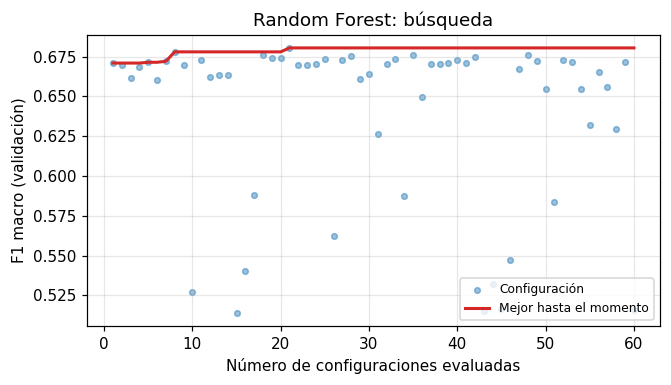

[Extra-Trees] configuraciones evaluadas: 60 (fallidas: 0) | tiempo de búsqueda: 283.4 s | mejor f1_macro: 0.6675
      clf__bootstrap: False
      clf__class_weight: balanced
      clf__criterion: gini
      clf__max_depth: 20
      clf__max_features: 0.7
      clf__min_samples_leaf: 3
      prep__nom__min_frequency: 0.005


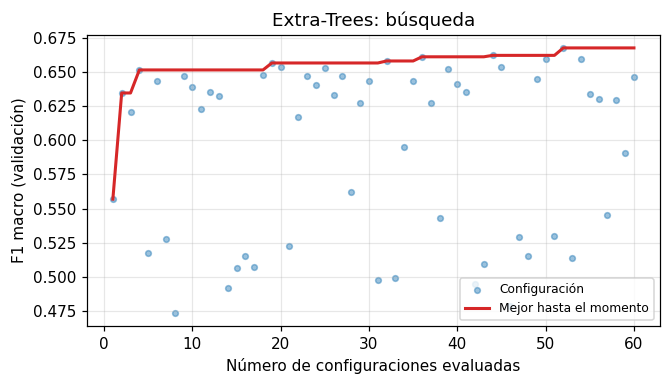

Random Forest                                F1 macro = 0.6805 ± 0.0077 | sens_enrolled = 0.471 | fit/pliegue = 2.2 s
Extra-Trees                                  F1 macro = 0.6675 ± 0.0093 | sens_enrolled = 0.441 | fit/pliegue = 6.7 s


In [11]:
SEARCHES = {}       # nombre -> dict(search, secs)

def run_search(name, pipe, space, X_, y_, cv_, n_iter, scoring="f1_macro", seed=SEED):
    t0 = time.perf_counter()
    s = RandomizedSearchCV(pipe, space, n_iter=n_iter, scoring=scoring, cv=cv_, random_state=seed,
                           n_jobs=-1, refit=True, error_score=np.nan)
    s.fit(X_, y_)
    secs = time.perf_counter() - t0
    n_fail = int(np.isnan(s.cv_results_["mean_test_score"]).sum())
    SEARCHES[name] = dict(search=s, secs=secs)
    print(f"[{name}] configuraciones evaluadas: {len(s.cv_results_['params'])} (fallidas: {n_fail}) | "
          f"tiempo de búsqueda: {secs:,.1f} s | mejor {scoring}: {s.best_score_:.4f}")
    for k, v in s.best_params_.items():
        print(f"      {k}: {v if not hasattr(v, 'get_params') else type(v).__name__}")
    return s

def plot_plateau(name, fname=None, ylabel="F1 macro (validación)"):
    s = SEARCHES[name]["search"]
    sc = np.asarray(s.cv_results_["mean_test_score"], dtype=float)
    best = np.maximum.accumulate(np.nan_to_num(sc, nan=-np.inf)); k = np.arange(1, len(sc) + 1)
    fig, ax = plt.subplots(figsize=(6.2, 3.6))
    ax.scatter(k, sc, s=14, alpha=.45, label="Configuración")
    ax.plot(k, best, color="C3", lw=2, label="Mejor hasta el momento")
    ax.set_xlabel("Número de configuraciones evaluadas"); ax.set_ylabel(ylabel); ax.set_title(f"{name}: búsqueda")
    ax.legend(fontsize=8, loc="lower right"); fig.tight_layout()
    import re; fig.savefig(OUT_DIR / (fname or "meseta_" + re.sub(r"[^\w\-]+", "_", name.lower()).strip("_") + ".png")); plt.show()

def short_cfg(params):
    return ", ".join(f"{k.split('__')[-1]}={(round(v, 4) if isinstance(v, float) else v)}" for k, v in params.items()
                     if not hasattr(v, "get_params"))

def register_search(name, family, X_, y_, cv_, scoring, sens_col, rows):
    r = SEARCHES[name]; s = r["search"]
    evaluate(name, s.best_estimator_, X_, y_, cv_, scoring, sens_col, rows, search_time=r["secs"],
             config=short_cfg(s.best_params_), family=family)

MAXF = ["sqrt", "log2", 0.2, 0.3, 0.5, 0.7]
space_trees = {
    "clf__max_features":     MAXF,
    "clf__max_depth":        [None, 5, 8, 12, 20],
    "clf__min_samples_leaf": randint(1, 31),
    "clf__criterion":        ["gini", "entropy", "log_loss"],
    "clf__class_weight":     [None, "balanced", "balanced_subsample"],
    "prep__nom__min_frequency": [0.005, 0.01, 0.03],
}
pipe_rf = Pipeline([("prep", make_prep(False)), ("clf", RandomForestClassifier(n_estimators=200, n_jobs=1, random_state=SEED))])
pipe_et = Pipeline([("prep", make_prep(False)), ("clf", ExtraTreesClassifier(n_estimators=200, n_jobs=1, random_state=SEED))])

run_search("Random Forest", pipe_rf, space_trees, X, y, cv, N_ITER)
plot_plateau("Random Forest")
run_search("Extra-Trees", pipe_et, {**space_trees, "clf__bootstrap": [True, False]}, X, y, cv, N_ITER)
plot_plateau("Extra-Trees")

register_search("Random Forest", "bagging optimizado", X, y, cv, SCORING_DES, "sens_enrolled", ROWS_DES)
register_search("Extra-Trees",   "bagging optimizado", X, y, cv, SCORING_DES, "sens_enrolled", ROWS_DES)

### Lectura de las gráficas de meseta (Random Forest y Extra-Trees)

- **Random Forest.** La curva de "mejor hasta el momento" llega a 0.6805 hacia la configuración ≈ 21 y no vuelve a moverse en las 39 restantes: la búsqueda alcanzó la meseta. La mejor configuración usa `max_features = 0.2` (pocos atributos por división, lo que decorrela los árboles), hojas de al menos 5 muestras, profundidad sin límite, `criterion = log_loss` y `class_weight = balanced_subsample`. Varias configuraciones se desploman a 0.51–0.59, así que hay combinaciones de hiperparámetros claramente malas.
- **Extra-Trees.** La meseta es menos limpia: sube a ≈ 0.656 hacia la configuración 18, a ≈ 0.661 hacia la 36 y a 0.667 hacia la 52, de modo que todavía mejoraba un poco al final (≈ +0.01 en 40 configuraciones); más configuraciones podrían sumar algunas milésimas. Ganó sin bootstrap (`bootstrap = False`), con `max_features = 0.7`, profundidad 20, hojas de 3 muestras y `class_weight = balanced`.
- **Comparación.** Random Forest (0.681 ± 0.008) supera al bagging simple (0.660) en +0.021, lo que muestra el valor de decorrelacionar los árboles con `max_features`, pero **empata con la regresión logística (0.679)**: no hay evidencia de ganancia. Extra-Trees (0.668) queda ligeramente por debajo de ambos. Los dos tienen sensibilidad de `enrolled` baja (0.47 y 0.44) frente a la regresión logística (0.575) y al SVM (0.578), a pesar de usar pesos por clase.

## 5. Boosting optimizado: XGBoost y LightGBM

Se eligieron **XGBoost** y **LightGBM** (editable en la configuración). Para poder buscar el **peso por clase** en ambos con la misma interfaz, se usa un pequeño envoltorio (`WeightedBoost`) que convierte `class_weight` en `sample_weight` (el equivalente a `class_weight="balanced"`) y codifica las etiquetas como enteros, que es lo que exigen estas bibliotecas.

Espacio de búsqueda (N_ITER configuraciones cada uno):

| Hiperparámetro | XGBoost | LightGBM |
|---|---|---|
| Tasa de aprendizaje | `learning_rate` ∈ [0.01, 0.3] (log) | igual |
| Nº de árboles | {100, 200, 300, 500} | igual |
| Profundidad / hojas | `max_depth` ∈ {2,…,8} | `num_leaves` ∈ [4, 64) (y `max_depth` sin límite) |
| Regularización de hojas | `min_child_weight` ∈ [1, 20] (log), `reg_lambda`, `reg_alpha`, `gamma` | `min_child_samples` ∈ [5, 80), `reg_lambda`, `reg_alpha` |
| Submuestreo de filas | `subsample` ∈ [0.5, 1] | `subsample` ∈ [0.5, 1] (con `subsample_freq=1`) |
| Submuestreo de columnas | `colsample_bytree` ∈ [0.3, 1] | igual |
| Pesos por clase | None / balanced | None / balanced |

[XGBoost] configuraciones evaluadas: 60 (fallidas: 0) | tiempo de búsqueda: 281.0 s | mejor f1_macro: 0.6961
      clf__class_weight: balanced
      clf__estimator__colsample_bytree: 0.7340928184610757
      clf__estimator__gamma: 0.010617558820142443
      clf__estimator__learning_rate: 0.018961721495508316
      clf__estimator__max_depth: 3
      clf__estimator__min_child_weight: 3.199991420534486
      clf__estimator__n_estimators: 500
      clf__estimator__reg_alpha: 0.21608491389795742
      clf__estimator__reg_lambda: 0.019388226757679754
      clf__estimator__subsample: 0.9871974038330833


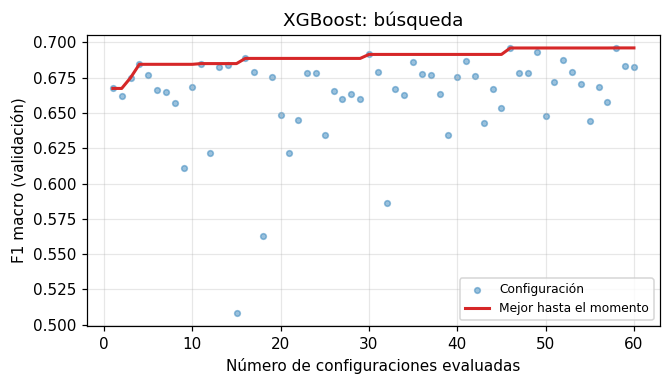

XGBoost                                      F1 macro = 0.6961 ± 0.0114 | sens_enrolled = 0.627 | fit/pliegue = 1.7 s
[LightGBM] configuraciones evaluadas: 60 (fallidas: 0) | tiempo de búsqueda: 232.0 s | mejor f1_macro: 0.6893
      clf__class_weight: balanced
      clf__estimator__colsample_bytree: 0.9337454493692445
      clf__estimator__learning_rate: 0.019462886350651437
      clf__estimator__min_child_samples: 17
      clf__estimator__n_estimators: 500
      clf__estimator__num_leaves: 34
      clf__estimator__reg_alpha: 0.032287642276066585
      clf__estimator__reg_lambda: 0.013935528944862288
      clf__estimator__subsample: 0.8091269421689464


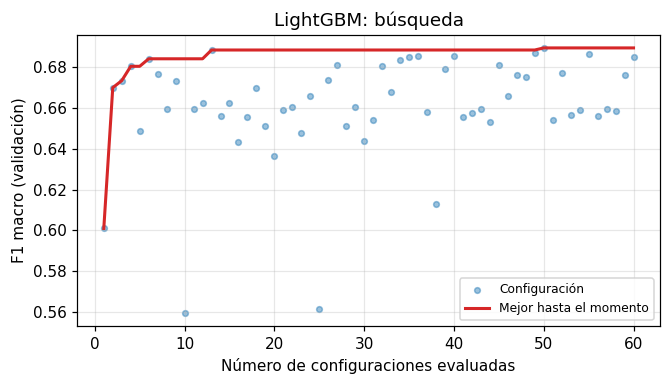

LightGBM                                     F1 macro = 0.6893 ± 0.0165 | sens_enrolled = 0.465 | fit/pliegue = 3.0 s


In [12]:
class WeightedBoost(ClassifierMixin, BaseEstimator):
    # Envoltorio: class_weight -> sample_weight, y etiquetas a enteros (requerido por XGBoost).
    def __init__(self, estimator=None, class_weight=None):
        self.estimator = estimator
        self.class_weight = class_weight
    def fit(self, X, y):
        self.le_ = LabelEncoder().fit(y)
        yi = self.le_.transform(y)
        sw = compute_sample_weight(self.class_weight, yi) if self.class_weight else None
        self.estimator_ = clone(self.estimator).fit(X, yi, sample_weight=sw)
        self.classes_ = self.le_.classes_
        return self
    def predict(self, X):
        return self.le_.inverse_transform(np.asarray(self.estimator_.predict(X)).astype(int).ravel())
    def predict_proba(self, X):
        return self.estimator_.predict_proba(X)

def make_xgb(**kw):
    return XGBClassifier(tree_method="hist", n_jobs=1, random_state=SEED, verbosity=0, **kw)
def make_lgbm(**kw):
    return LGBMClassifier(n_jobs=1, random_state=SEED, verbose=-1, subsample_freq=1, **kw)

space_xgb = {
    "clf__class_weight":                  [None, "balanced"],
    "clf__estimator__learning_rate":      loguniform(1e-2, 3e-1),
    "clf__estimator__n_estimators":       [100, 200, 300, 500],
    "clf__estimator__max_depth":          randint(2, 9),
    "clf__estimator__min_child_weight":   loguniform(1, 20),
    "clf__estimator__reg_lambda":         loguniform(1e-2, 50),
    "clf__estimator__reg_alpha":          loguniform(1e-3, 10),
    "clf__estimator__gamma":              loguniform(1e-3, 5),
    "clf__estimator__subsample":          uniform(0.5, 0.5),
    "clf__estimator__colsample_bytree":   uniform(0.3, 0.7),
}
space_lgbm = {
    "clf__class_weight":                  [None, "balanced"],
    "clf__estimator__learning_rate":      loguniform(1e-2, 3e-1),
    "clf__estimator__n_estimators":       [100, 200, 300, 500],
    "clf__estimator__num_leaves":         randint(4, 64),
    "clf__estimator__min_child_samples":  randint(5, 80),
    "clf__estimator__reg_lambda":         loguniform(1e-2, 50),
    "clf__estimator__reg_alpha":          loguniform(1e-3, 10),
    "clf__estimator__subsample":          uniform(0.5, 0.5),
    "clf__estimator__colsample_bytree":   uniform(0.3, 0.7),
}
BOOST = {}
if XGBClassifier is not None:  BOOST["XGBoost"]  = (make_xgb,  space_xgb)
if LGBMClassifier is not None: BOOST["LightGBM"] = (make_lgbm, space_lgbm)

for name, (factory, space) in BOOST.items():
    pipe = Pipeline([("prep", make_prep(False)), ("clf", WeightedBoost(estimator=factory()))])
    run_search(name, pipe, space, X, y, cv, N_ITER)
    plot_plateau(name)
    register_search(name, "boosting optimizado", X, y, cv, SCORING_DES, "sens_enrolled", ROWS_DES)

### Lectura de las gráficas de meseta (boosting)

- **LightGBM.** Alcanza 0.688 hacia la configuración ≈ 13 y apenas se mueve después (0.689 en la 50): meseta clara. **XGBoost** llega a ≈ 0.688 hacia la 16, pero sigue avanzando por escalones pequeños (≈ 0.691 hacia la 30 y 0.696 hacia la 46 y 58); la meseta no es del todo plana y una búsqueda más larga podría ganar unas milésimas.
- **Qué hiperparámetros ganaron.** En ambos, **tasa de aprendizaje baja (≈ 0.019) con el máximo de árboles del espacio (500)**, árboles poco profundos (XGBoost: `max_depth = 3`; LightGBM: 34 hojas) y `class_weight = balanced`. Es decir, boosting lento y regularizado. Como 500 es el límite superior de `n_estimators`, no se descarta que más árboles con esa tasa ayuden un poco. XGBoost eligió además `min_child_weight` ≈ 3.2 y casi sin submuestreo de filas (0.99) pero con submuestreo de columnas (0.73); LightGBM, `min_child_samples = 17` y submuestreo de filas 0.81.
- **Resultados.** XGBoost 0.696 ± 0.011 y LightGBM 0.689 ± 0.016, frente a AdaBoost con tocones (0.638): +0.058 y +0.051, porque aprenden árboles más expresivos con gradiente en lugar de tocones, además de usar regularización. Frente a la regresión logística (0.679) la ganancia es **+0.017 (XGBoost)** y +0.010 (LightGBM), del orden de la desviación entre pliegues (≈ 0.011–0.016): mejora **modesta y no concluyente**. La diferencia entre XGBoost y LightGBM (0.007) está dentro del ruido.
- **Sensibilidad de `enrolled`.** Aunque tienen F1 macro parecido, XGBoost detecta mucho mejor a `enrolled` (0.627) que LightGBM (0.465).
- **Qué dice sobre el problema.** Con solo 3539 filas y 30 atributos, los modelos de mayor capacidad ganan poco sobre un modelo lineal regularizado: el problema parece cercano a lineal y limitado por la información del primer semestre.

## 6. Tabla final de deserción y matriz de confusión del mejor modelo

Todos los modelos evaluados con `cross_validate` y los **mismos cinco pliegues**, ordenados por F1 macro (media ± desviación entre pliegues). Para los modelos optimizados se reporta la mejor configuración encontrada. La sensibilidad es la de la clase `enrolled`, y el tiempo es el de entrenamiento por pliegue (la búsqueda, cuando existe, va en su propia columna).

In [13]:
tabla = pd.DataFrame(ROWS_DES).sort_values("F1 macro (media)", ascending=False).reset_index(drop=True)
tabla.insert(2, "F1 macro (media ± desv.)", tabla.apply(lambda r: f"{r['F1 macro (media)']:.3f} ± {r['F1 macro (desv.)']:.3f}", axis=1))
cols = ["modelo", "familia", "F1 macro (media ± desv.)", "sens_enrolled", "t. entrenamiento por pliegue (s)", "t. búsqueda (s)", "configuración"]
tabla[cols].to_csv(OUT_DIR / "tabla_desercion.csv", index=False)
display(tabla[cols].round({"sens_enrolled": 3, "t. entrenamiento por pliegue (s)": 1, "t. búsqueda (s)": 0}))
BEST1 = tabla.loc[0, "modelo"]; print("Mejor modelo de deserción:", BEST1)

,modelo,familia,F1 macro (media ± desv.),sens_enrolled,t. entrenamiento por pliegue (s),t. búsqueda (s),configuración
0,XGBoost,boosting optimizado,0.696 ± 0.011,0.627,1.7,281.0,"class_weight=balanced, colsample_bytree=0.7341, gamma=0.0106, learning_rate=0.019, max..."
1,LightGBM,boosting optimizado,0.689 ± 0.016,0.465,3.0,232.0,"class_weight=balanced, colsample_bytree=0.9337, learning_rate=0.0195, min_child_sample..."
2,Stacking (meta: reg. logística),combinar base,0.687 ± 0.008,0.617,24.7,NaN,
3,Votación dura (5 base),combinar base,0.681 ± 0.013,0.542,3.2,NaN,
4,Random Forest,bagging optimizado,0.681 ± 0.008,0.471,2.2,395.0,"class_weight=balanced_subsample, criterion=log_loss, max_depth=None, max_features=0.2,..."
5,Regresión logística,base (Práctica 3),0.679 ± 0.011,0.575,2.1,NaN,
6,Votación suave (5 base),combinar base,0.678 ± 0.011,0.452,4.3,NaN,
7,SVM,base (Práctica 3),0.676 ± 0.008,0.578,1.3,NaN,
8,Extra-Trees,bagging optimizado,0.668 ± 0.009,0.441,6.7,283.0,"bootstrap=False, class_weight=balanced, criterion=gini, max_depth=20, max_features=0.7..."
9,Bagging (400 árboles sin límite),varianza,0.660 ± 0.022,0.340,14.7,NaN,"n_estimators=400, bootstrap, warm_start"


Mejor modelo de deserción: XGBoost


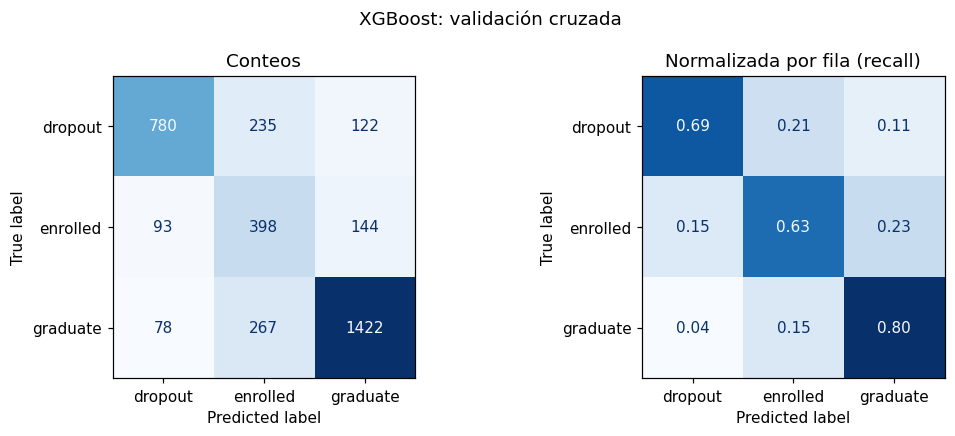

In [14]:
# Matriz de confusión únicamente del mejor modelo (predicciones de validación cruzada, mismos pliegues)
def get_model_des(name):
    if name in BASE: return BASE[name]
    if name in SEARCHES: return SEARCHES[name]["search"].best_estimator_
    return {"Árbol sin límite de profundidad": pipe_tree_full, "Tocón (profundidad 1)": pipe_stump,
            "Votación dura (5 base)": vote_hard, "Votación suave (5 base)": vote_soft,
            "Stacking (meta: reg. logística)": stack}.get(name)

best_model_des = get_model_des(BEST1)
if best_model_des is None:
    print("El mejor modelo es una curva (bagging/AdaBoost sin objeto único); se omite la matriz.")
else:
    y_cv = cross_val_predict(clone(best_model_des), X, y, cv=cv, n_jobs=CV_JOBS)
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    ConfusionMatrixDisplay.from_predictions(y, y_cv, labels=LABELS, ax=axes[0], colorbar=False, cmap="Blues"); axes[0].set_title("Conteos")
    ConfusionMatrixDisplay.from_predictions(y, y_cv, labels=LABELS, normalize="true", ax=axes[1], colorbar=False, cmap="Blues", values_format=".2f")
    axes[1].set_title("Normalizada por fila (recall)")
    for a in axes: a.grid(False)
    fig.suptitle(f"{BEST1}: validación cruzada"); fig.tight_layout(); fig.savefig(OUT_DIR / "matriz_confusion_desercion.png"); plt.show()

### Resumen de la Parte 1

**¿Cuánto ganan los ensambles sobre los cinco base ya ajustados?** Poco. El mejor base es la regresión logística (0.679 ± 0.011) y el mejor ensamble es **XGBoost (0.696 ± 0.011)**: **+0.017**, es decir, ≈ 1.5 desviaciones entre pliegues y ≈ 2.5 % relativo. El stacking (0.687) suma +0.008; LightGBM (0.689) +0.010; Random Forest (0.681), votación dura (0.681) y votación suave (0.678) **no mejoran** al mejor base. Una parte de esa ganancia pequeña podría deberse a que los modelos optimizados se eligieron en los mismos pliegues (sesgo de selección), lo mismo que ocurre con los base.

**Por familia**
- **Varianza (bagging, Random Forest, Extra-Trees):** mejoran mucho a un árbol sin límite (+0.069 el bagging) pero no superan al modelo lineal; Random Forest iguala a la regresión logística y Extra-Trees queda ligeramente por debajo.
- **Sesgo (AdaBoost, XGBoost, LightGBM):** AdaBoost con tocones corrige mucho un modelo muy sesgado (+0.146) pero no llega a la regresión logística; el boosting con árboles regularizados (XGBoost, LightGBM) es la única familia que la supera, y por poco.
- **Combinación (votación, stacking):** poca ganancia por la correlación de errores (media 0.52; 11.7 % de estudiantes que ningún modelo acierta). El stacking es lo más útil de este grupo, pero 12 veces más lento.

**Costo.** XGBoost entrena en 1.7 s por pliegue (similar a la regresión logística, 2.1 s) pero su búsqueda tomó 281 s; Random Forest tardó 395 s de búsqueda; el stacking cuesta 24.7 s por pliegue; el bagging de 400 árboles, 14.7 s. XGBoost es el mejor compromiso: mejor F1, mejor sensibilidad de `enrolled` y entrenamiento rápido.

**Sensibilidad de `enrolled` (la clase más difícil).** Los mejores son XGBoost (0.627) y el stacking (0.617), por encima del SVM (0.578) y la regresión logística (0.575). Los modelos de árboles sin ese ajuste (Random Forest 0.471, LightGBM 0.465, Extra-Trees 0.441, AdaBoost 0.272, bagging 0.340) la sacrifican.

**Matriz de confusión del mejor modelo (XGBoost).** Recall de `dropout` 0.69 (780 de 1137): 21 % se confunde con `enrolled` y 11 % con `graduate`; `enrolled` 0.63 (398 de 635), con 23 % hacia `graduate` y 15 % hacia `dropout`; `graduate` 0.80 (1422 de 1767). El patrón de errores es el mismo que en la Práctica 3 (desertores que se parecen a inscritos y graduados), con una mejora en `enrolled` respecto a la regresión logística (0.575 → 0.627).

## 7. Parte 2 — Bank Marketing (Tarea 4)

**Problema.** Predecir si un cliente contratará un depósito a plazo (`y`: `yes`/`no`) con `bank-additional-full.csv` (41 188 instancias, ~11 % de `yes`), **sin la columna `duration`** (no se conoce antes de la llamada). Evaluación obligatoria: `cross_validate(modelo, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=2026), scoring="f1_macro")`, con `y` en 1 (`yes`) y 0 (`no`).

**Reglas que se respetan.**
- Todo lo que se ajusta con datos (codificación, escalamiento, **umbral de decisión**, calibración) va **dentro del modelo** (`Pipeline`, `TunedThresholdClassifierCV`, `StackingClassifier`), así que se ajusta solo con los pliegues de entrenamiento.
- Los hiperparámetros se buscan con `RandomizedSearchCV` sobre una **submuestra estratificada** (`SEARCH_FRAC` de las filas) y con pliegues distintos a los de evaluación (otra semilla, 3 pliegues), optimizando `average_precision` (independiente del umbral). Luego el mejor de cada familia se evalúa en las 41 188 filas con los pliegues oficiales. Nota: la submuestra sale de las mismas filas, por lo que hay una optimización leve; los pliegues de evaluación no se usaron para elegir hiperparámetros.
- **Umbral.** Con ~11 % de `yes`, el umbral 0.5 no maximiza el F1 macro; `TunedThresholdClassifierCV` elige el umbral que lo maximiza usando validación cruzada interna del pliegue de entrenamiento.

**Preprocesamiento.** Categóricas con one-hot (`unknown` se trata como una categoría más); numéricas estandarizadas solo para los modelos que lo requieren (regresión logística); `pdays == 999` ("sin contacto previo") se convierte en el indicador `no_prev_contact` y se reemplaza por 0 en `pdays`. Esta transformación no aprende nada de los datos, por lo que no hay fuga.

In [16]:
bank = pd.read_csv(DATA_DIR / "bank-additional/bank-additional/bank-additional-full.csv", sep=";")
if BANK_N: bank = bank.sample(int(BANK_N), random_state=SEED_BANK).reset_index(drop=True)      # solo pruebas rápidas
yb = (bank["y"] == "yes").astype(int)
Xb = bank.drop(columns=["y", "duration"])
print(Xb.shape, "| yes:", f"{yb.mean():.3%}", "| duration en X:", "duration" in Xb.columns)

CAT_B = ["job", "marital", "education", "default", "housing", "loan", "contact", "month", "day_of_week", "poutcome"]
NUM_B = ["age", "campaign", "pdays", "previous", "emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
assert set(CAT_B + NUM_B) == set(Xb.columns), set(Xb.columns) ^ set(CAT_B + NUM_B)
print("pdays == 999:", f"{(Xb['pdays'] == 999).mean():.1%}", "| 'unknown' por columna:",
      {c: int((Xb[c] == "unknown").sum()) for c in CAT_B if (Xb[c] == "unknown").any()})

def fe_bank(df):
    df = df.copy()
    df["no_prev_contact"] = (df["pdays"] == 999).astype(int)
    df["pdays"] = df["pdays"].where(df["pdays"] != 999, 0)
    return df

def make_prep_bank(scale):
    return Pipeline([("fe", FunctionTransformer(fe_bank)),
                     ("ct", ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_B),
                                               ("num", StandardScaler() if scale else "passthrough", NUM_B),
                                               ("flag", "passthrough", ["no_prev_contact"])]))])

def bank_pipe(clf, scale=False):
    return Pipeline([("prep", make_prep_bank(scale)), ("clf", clf)])

cv_bank   = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED_BANK)       # pliegues oficiales
cv_search = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED_BANK + 1)   # pliegues solo para buscar
SCORING_BANK = {"f1_macro": "f1_macro", "sens_yes": make_scorer(recall_score, pos_label=1, zero_division=0)}
ROWS_BANK, MODELS_BANK = [], {}

Xs, _, ys, _ = train_test_split(Xb, yb, train_size=min(SEARCH_FRAC, 0.999), stratify=yb, random_state=SEED_BANK)
print(f"Submuestra para buscar hiperparámetros: {len(Xs)} filas ({ys.mean():.3%} yes)")

def with_threshold(est, inner_folds=3):
    # El umbral se ajusta dentro de cada pliegue de entrenamiento, maximizando el F1 macro
    return TunedThresholdClassifierCV(est, scoring="f1_macro", cv=StratifiedKFold(inner_folds, shuffle=True, random_state=SEED_BANK),
                                      refit=True, thresholds=50, n_jobs=1)

(41188, 19) | yes: 11.265% | duration en X: False
pdays == 999: 96.3% | 'unknown' por columna: {'job': 330, 'marital': 80, 'education': 1731, 'default': 8597, 'housing': 990, 'loan': 990}
Submuestra para buscar hiperparámetros: 12356 filas (11.266% yes)


### Búsqueda de hiperparámetros por familia

Seis familias, cada una con **N_ITER_BANK** configuraciones (≥ 50): regresión logística, Random Forest, Extra-Trees, HistGradientBoosting (scikit-learn), LightGBM y XGBoost. Cada una incluye `class_weight` entre sus hiperparámetros (balanceo de clases).

[B: Reg. logística] configuraciones evaluadas: 50 (fallidas: 0) | tiempo de búsqueda: 20.8 s | mejor average_precision: 0.4386
      clf__C: 0.15488987921586306
      clf__class_weight: None


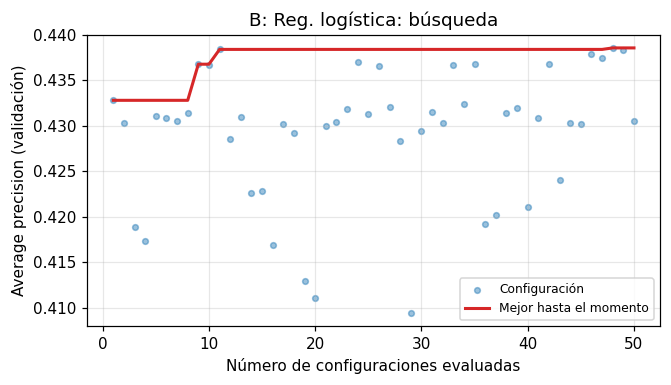

[B: Random Forest] configuraciones evaluadas: 50 (fallidas: 0) | tiempo de búsqueda: 267.4 s | mejor average_precision: 0.4581
      clf__class_weight: None
      clf__criterion: gini
      clf__max_depth: 12
      clf__max_features: 0.3
      clf__min_samples_leaf: 19


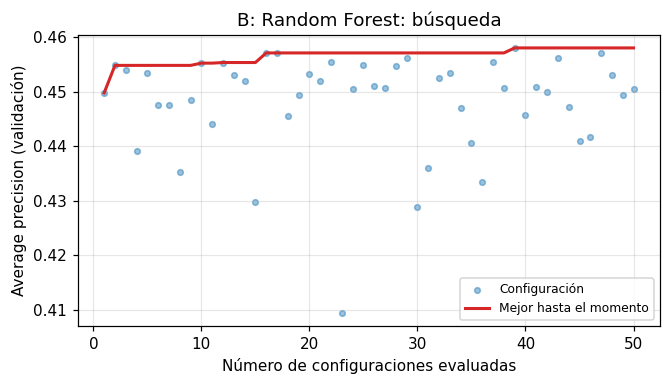

[B: Extra-Trees] configuraciones evaluadas: 50 (fallidas: 0) | tiempo de búsqueda: 233.4 s | mejor average_precision: 0.4567
      clf__bootstrap: False
      clf__class_weight: balanced
      clf__criterion: gini
      clf__max_depth: 8
      clf__max_features: 0.3
      clf__min_samples_leaf: 11


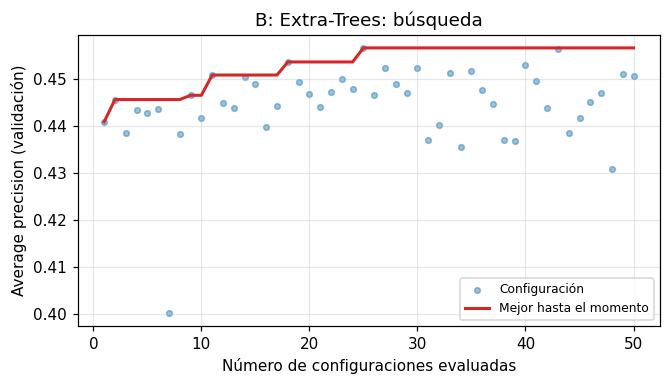

[B: HistGradientBoosting] configuraciones evaluadas: 50 (fallidas: 0) | tiempo de búsqueda: 341.4 s | mejor average_precision: 0.4540
      clf__class_weight: None
      clf__l2_regularization: 1.0397385621283324
      clf__learning_rate: 0.0876350680194838
      clf__max_leaf_nodes: 5
      clf__min_samples_leaf: 30


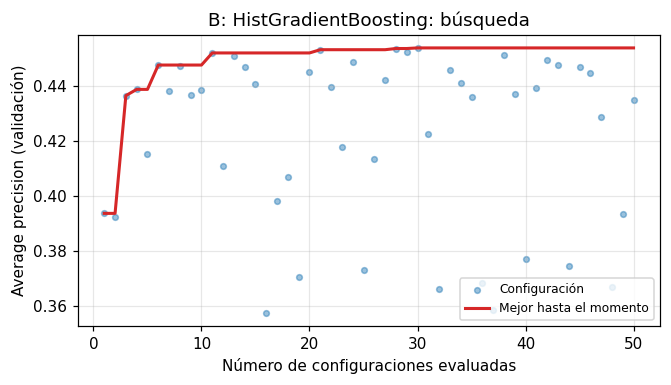

[B: LightGBM] configuraciones evaluadas: 50 (fallidas: 0) | tiempo de búsqueda: 86.0 s | mejor average_precision: 0.4599
      clf__class_weight: None
      clf__estimator__colsample_bytree: 0.579391273486517
      clf__estimator__learning_rate: 0.016934692558110732
      clf__estimator__min_child_samples: 24
      clf__estimator__n_estimators: 300
      clf__estimator__num_leaves: 42
      clf__estimator__reg_alpha: 2.0599818200626245
      clf__estimator__reg_lambda: 0.014768322158176585
      clf__estimator__subsample: 0.7344325895194966


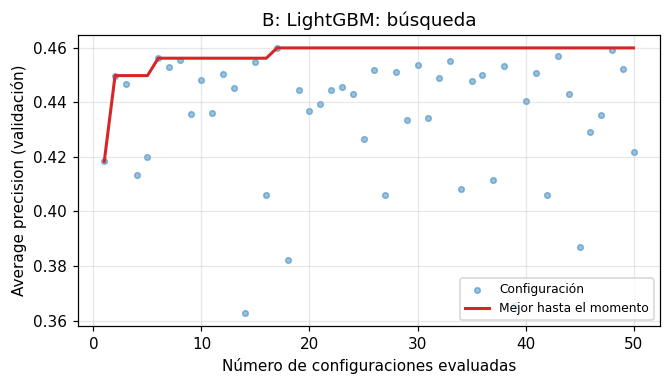

[B: XGBoost] configuraciones evaluadas: 50 (fallidas: 0) | tiempo de búsqueda: 94.7 s | mejor average_precision: 0.4594
      clf__class_weight: None
      clf__estimator__colsample_bytree: 0.353513056461206
      clf__estimator__gamma: 1.8095816304220371
      clf__estimator__learning_rate: 0.08655726539530181
      clf__estimator__max_depth: 8
      clf__estimator__min_child_weight: 1.393078046270565
      clf__estimator__n_estimators: 300
      clf__estimator__reg_alpha: 0.0015838692900663788
      clf__estimator__reg_lambda: 13.288432894223497
      clf__estimator__subsample: 0.7851099039098401


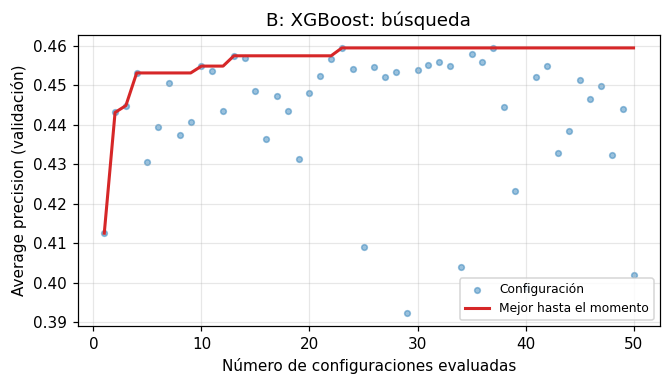

In [17]:
SEARCHES_B_START = set(SEARCHES)
space_trees_b = {k: v for k, v in space_trees.items() if not k.startswith("prep")}

fams = {
    "Reg. logística": (bank_pipe(LogisticRegression(max_iter=2000, random_state=SEED_BANK), scale=True),
                       {"clf__C": loguniform(1e-3, 1e2), "clf__class_weight": [None, "balanced"]}),
    "Random Forest": (bank_pipe(RandomForestClassifier(n_estimators=150, n_jobs=1, random_state=SEED_BANK)), space_trees_b),
    "Extra-Trees":   (bank_pipe(ExtraTreesClassifier(n_estimators=150, n_jobs=1, random_state=SEED_BANK)),
                      {**space_trees_b, "clf__bootstrap": [True, False]}),
    "HistGradientBoosting": (bank_pipe(HistGradientBoostingClassifier(max_iter=300, early_stopping=False, random_state=SEED_BANK)),
                      {"clf__learning_rate": loguniform(1e-2, 3e-1), "clf__max_leaf_nodes": randint(4, 64),
                       "clf__min_samples_leaf": randint(5, 100), "clf__l2_regularization": loguniform(1e-3, 50),
                       "clf__class_weight": [None, "balanced"]}),
}
if LGBMClassifier is not None:
    fams["LightGBM"] = (bank_pipe(WeightedBoost(estimator=make_lgbm())), space_lgbm)
if XGBClassifier is not None:
    fams["XGBoost"] = (bank_pipe(WeightedBoost(estimator=make_xgb())), space_xgb)

for name, (pipe, space) in fams.items():
    run_search(f"B: {name}", pipe, space, Xs, ys, cv_search, N_ITER_BANK, scoring="average_precision", seed=SEED_BANK)
    plot_plateau(f"B: {name}", ylabel="Average precision (validación)")

### Evaluación oficial en las 41 188 filas

Cada mejor configuración se evalúa con `cross_validate` y los pliegues oficiales (`random_state=2026`), **sin y con umbral ajustado**. También se evalúan una votación suave y un *stacking* (meta-modelo logístico) con los mejores modelos de cada familia, con umbral ajustado.

In [18]:
def eval_bank(name, model, family, search_time=np.nan, config=""):
    MODELS_BANK[name] = model
    return evaluate(name, model, Xb, yb, cv_bank, SCORING_BANK, "sens_yes", ROWS_BANK,
                    search_time=search_time, config=config, family=family)

best_b = {}
for name in fams:
    r = SEARCHES[f"B: {name}"]; best_b[name] = r["search"].best_estimator_
    cfg = short_cfg(r["search"].best_params_)
    eval_bank(f"{name} (sin umbral)", best_b[name], "una familia", r["secs"], cfg)
    if TunedThresholdClassifierCV is not None:
        eval_bank(f"{name} + umbral", with_threshold(clone(best_b[name])), "una familia + umbral", r["secs"], cfg)

Reg. logística (sin umbral)                  F1 macro = 0.6410 ± 0.0101 | sens_yes = 0.225 | fit/pliegue = 0.5 s
Reg. logística + umbral                      F1 macro = 0.7071 ± 0.0056 | sens_yes = 0.533 | fit/pliegue = 3.0 s
Random Forest (sin umbral)                   F1 macro = 0.6580 ± 0.0099 | sens_yes = 0.257 | fit/pliegue = 12.3 s
Random Forest + umbral                       F1 macro = 0.7173 ± 0.0069 | sens_yes = 0.547 | fit/pliegue = 36.2 s
Extra-Trees (sin umbral)                     F1 macro = 0.6902 ± 0.0059 | sens_yes = 0.614 | fit/pliegue = 12.2 s
Extra-Trees + umbral                         F1 macro = 0.7141 ± 0.0061 | sens_yes = 0.552 | fit/pliegue = 34.3 s
HistGradientBoosting (sin umbral)            F1 macro = 0.6547 ± 0.0091 | sens_yes = 0.251 | fit/pliegue = 5.2 s
HistGradientBoosting + umbral                F1 macro = 0.7141 ± 0.0057 | sens_yes = 0.537 | fit/pliegue = 18.7 s
LightGBM (sin umbral)                        F1 macro = 0.6621 ± 0.0119 | sens_yes = 0.266 

In [19]:
# Ensambles de los mejores de cada familia (con umbral ajustado dentro del modelo)
members = [(n, clone(best_b[n])) for n in ("Reg. logística", "Random Forest", "LightGBM", "XGBoost", "HistGradientBoosting") if n in best_b]
vote_b  = VotingClassifier(members, voting="soft", n_jobs=1)
stack_b = StackingClassifier(members, final_estimator=LogisticRegression(C=1.0, max_iter=2000), cv=StratifiedKFold(3, shuffle=True, random_state=SEED_BANK),
                             stack_method="predict_proba", n_jobs=1)   # shuffle=True: los datos vienen ordenados por fecha
eval_bank("Votación suave", vote_b, "ensamble")
eval_bank("Stacking (meta: reg. logística)", stack_b, "ensamble")
if TunedThresholdClassifierCV is not None:
    eval_bank("Votación suave + umbral", with_threshold(clone(vote_b)), "ensamble + umbral")
    eval_bank("Stacking + umbral", with_threshold(clone(stack_b)), "ensamble + umbral")

Votación suave                               F1 macro = 0.6526 ± 0.0110 | sens_yes = 0.245 | fit/pliegue = 22.7 s
Stacking (meta: reg. logística)              F1 macro = 0.5000 ± 0.0067 | sens_yes = 0.039 | fit/pliegue = 67.2 s
Votación suave + umbral                      F1 macro = 0.7178 ± 0.0066 | sens_yes = 0.546 | fit/pliegue = 72.8 s
Stacking + umbral                            F1 macro = 0.5326 ± 0.0090 | sens_yes = 0.140 | fit/pliegue = 204.7 s


> **Nota importante sobre el stacking de Bank Marketing.** En la ejecución guardada de este notebook, el stacking colapsó (F1 macro 0.500 y 0.533 con umbral; sensibilidad de `yes` de 0.04 y 0.14), muy por debajo de la votación suave (0.653 sin umbral). La causa fue un detalle de validación cruzada: `StackingClassifier(cv=3)` usa `StratifiedKFold` **sin mezclar**, y `bank-additional-full.csv` está ordenado por fecha. Los pliegues internos eran entonces bloques cronológicos, y el meta-modelo se entrenaba con predicciones de miembros que nunca habían visto ese periodo (el contexto macroeconómico cambia con el tiempo), de modo que esas predicciones no representaban su desempeño real. Se comprobó por separado con dos miembros (regresión logística e `HistGradientBoosting`) sobre los datos completos y los mismos cinco pliegues oficiales: F1 macro 0.478 con `cv=3` sin mezclar y 0.656 con `StratifiedKFold(3, shuffle=True)`. La celda anterior ya está corregida con `shuffle=True`; **las cifras de stacking que aparecen en las salidas guardadas corresponden a la versión sin corregir**, y al volver a ejecutar cambiarán (también la tabla y, si el stacking pasara a ser el mejor, la matriz de confusión y el `.joblib`). En las conclusiones, el stacking de Bank se discute con esa salvedad.

In [20]:
tabla_b = pd.DataFrame(ROWS_BANK).sort_values("F1 macro (media)", ascending=False).reset_index(drop=True)
tabla_b.insert(2, "F1 macro (media ± desv.)", tabla_b.apply(lambda r: f"{r['F1 macro (media)']:.4f} ± {r['F1 macro (desv.)']:.4f}", axis=1))
cols_b = ["modelo", "familia", "F1 macro (media ± desv.)", "sens_yes", "t. entrenamiento por pliegue (s)", "t. búsqueda (s)", "configuración"]
tabla_b[cols_b].to_csv(OUT_DIR / "tabla_bank.csv", index=False)
display(tabla_b[cols_b].round({"sens_yes": 3, "t. entrenamiento por pliegue (s)": 1, "t. búsqueda (s)": 0}))
BEST_B = tabla_b.loc[0, "modelo"]
print("Mejor modelo de Bank Marketing:", BEST_B, "| F1 macro =", f"{tabla_b.loc[0, 'F1 macro (media)']:.4f}")
print("Mejor modelo de deserción (Parte 1):", BEST1)

,modelo,familia,F1 macro (media ± desv.),sens_yes,t. entrenamiento por pliegue (s),t. búsqueda (s),configuración
0,LightGBM + umbral,una familia + umbral,0.7178 ± 0.0061,0.538,12.5,86.0,"class_weight=None, colsample_bytree=0.5794, learning_rate=0.0169, min_child_samples=24..."
1,XGBoost + umbral,una familia + umbral,0.7178 ± 0.0047,0.547,9.5,95.0,"class_weight=None, colsample_bytree=0.3535, gamma=1.8096, learning_rate=0.0866, max_de..."
2,Votación suave + umbral,ensamble + umbral,0.7178 ± 0.0066,0.546,72.8,NaN,
3,Random Forest + umbral,una familia + umbral,0.7173 ± 0.0069,0.547,36.2,267.0,"class_weight=None, criterion=gini, max_depth=12, max_features=0.3, min_samples_leaf=19"
4,HistGradientBoosting + umbral,una familia + umbral,0.7141 ± 0.0057,0.537,18.7,341.0,"class_weight=None, l2_regularization=1.0397, learning_rate=0.0876, max_leaf_nodes=5, m..."
5,Extra-Trees + umbral,una familia + umbral,0.7141 ± 0.0061,0.552,34.3,233.0,"bootstrap=False, class_weight=balanced, criterion=gini, max_depth=8, max_features=0.3,..."
6,Reg. logística + umbral,una familia + umbral,0.7071 ± 0.0056,0.533,3.0,21.0,"C=0.1549, class_weight=None"
7,Extra-Trees (sin umbral),una familia,0.6902 ± 0.0059,0.614,12.2,233.0,"bootstrap=False, class_weight=balanced, criterion=gini, max_depth=8, max_features=0.3,..."
8,LightGBM (sin umbral),una familia,0.6621 ± 0.0119,0.266,2.5,86.0,"class_weight=None, colsample_bytree=0.5794, learning_rate=0.0169, min_child_samples=24..."
9,XGBoost (sin umbral),una familia,0.6606 ± 0.0088,0.264,2.3,95.0,"class_weight=None, colsample_bytree=0.3535, gamma=1.8096, learning_rate=0.0866, max_de..."


Mejor modelo de Bank Marketing: LightGBM + umbral | F1 macro = 0.7178
Mejor modelo de deserción (Parte 1): XGBoost


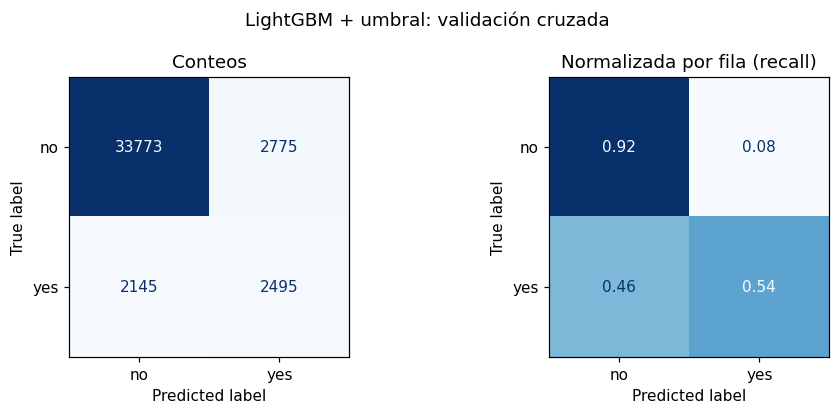

Sensibilidad yes = 0.538 | especificidad = 0.924 | precisión yes = 0.473


In [21]:
# Matriz de confusión del mejor modelo (predicciones de validación cruzada con los pliegues oficiales)
best_model_b = MODELS_BANK[BEST_B]
yb_cv = cross_val_predict(clone(best_model_b), Xb, yb, cv=cv_bank, n_jobs=CV_JOBS)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
ConfusionMatrixDisplay.from_predictions(yb, yb_cv, display_labels=["no", "yes"], ax=axes[0], colorbar=False, cmap="Blues"); axes[0].set_title("Conteos")
ConfusionMatrixDisplay.from_predictions(yb, yb_cv, display_labels=["no", "yes"], normalize="true", ax=axes[1], colorbar=False, cmap="Blues", values_format=".2f")
axes[1].set_title("Normalizada por fila (recall)")
for a in axes: a.grid(False)
fig.suptitle(f"{BEST_B}: validación cruzada"); fig.tight_layout(); fig.savefig(OUT_DIR / "matriz_confusion_bank.png"); plt.show()
tn, fp, fn, tp = confusion_matrix(yb, yb_cv).ravel()
print(f"Sensibilidad yes = {tp/(tp+fn):.3f} | especificidad = {tn/(tn+fp):.3f} | precisión yes = {tp/(tp+fp):.3f}")

In [22]:
# Modelo final: el mejor, reentrenado con TODAS las filas, guardado como Pipeline completo (.joblib)
final_b = clone(best_model_b).fit(Xb, yb)
JOBLIB_PATH = Path(f"{NOMBRE}_modelo.joblib")

# fe_bank y WeightedBoost están definidas en este notebook (__main__). Con joblib.dump normal el archivo solo se
# puede cargar si esas definiciones existen en quien lo abre. cloudpickle las guarda DENTRO del archivo, así que
# joblib.load funciona en cualquier entorno que tenga scikit-learn, xgboost y lightgbm.
try:
    import cloudpickle
    with open(JOBLIB_PATH, "wb") as f:
        cloudpickle.dump(final_b, f)
except ImportError:
    joblib.dump(final_b, JOBLIB_PATH)

# Verificación: se puede cargar y predice sobre el DataFrame crudo (sin duration ni y)
loaded = joblib.load(JOBLIB_PATH)
assert np.array_equal(loaded.predict(Xb.head(200)), final_b.predict(Xb.head(200)))
print("Guardado:", JOBLIB_PATH, f"({JOBLIB_PATH.stat().st_size/1e6:.1f} MB) | espera columnas:", list(Xb.columns))

Guardado: benjamin-hernandez_modelo.joblib (1.4 MB) | espera columnas: ['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']


**Cómo usar el archivo `.joblib`:** el archivo contiene un `Pipeline` completo (preprocesamiento + modelo + umbral). Se carga con `joblib.load` y se aplica a un `DataFrame` con las 19 columnas de `bank-additional-full.csv` sin `duration` ni `y`; devuelve 1 (`yes`) o 0 (`no`). Ver el README para el ejemplo completo y para el script `usar_modelo.py`.

### ¿Funcionó lo mismo que en la deserción, y por qué?

**Resultados de Bank Marketing (F1 macro, 5 pliegues, `random_state=2026`).** Los tres mejores modelos empatan en **0.718** a tres decimales: LightGBM + umbral (0.7178 ± 0.0061), XGBoost + umbral (0.7178 ± 0.0047) y votación suave + umbral (0.7178 ± 0.0066), seguidos por Random Forest + umbral (0.7173), HistGradientBoosting y Extra-Trees + umbral (0.7141) y regresión logística + umbral (0.7071). Las diferencias entre los cuatro primeros son del orden de 0.001, muy por debajo de la desviación entre pliegues (≈ 0.005–0.007): **no hay evidencia de que alguno sea mejor**. Se guardó LightGBM + umbral por aparecer primero en la tabla; XGBoost + umbral tiene la desviación más baja y es más rápido de entrenar.

**¿Funcionó lo mismo? Sí en lo esencial, y con diferencias importantes.**
- **Los ensambles de árboles ganan poco al modelo lineal en ambos problemas.** En deserción, XGBoost supera a la regresión logística por +0.017; en Bank, LightGBM/XGBoost + umbral superan a la regresión logística + umbral (0.7071) por **+0.011**, unas dos desviaciones entre pliegues. En Bank la diferencia es estadísticamente más visible (la desviación es ≈ 0.006 frente a ≈ 0.011 en deserción, porque hay 12 veces más filas), pero sigue siendo pequeña en términos prácticos. La búsqueda también lo muestra: la *average precision* de la regresión logística (0.439) y de los modelos de árboles y boosting (0.454–0.460) difieren en ≈ 0.02.
- **Lo que más cambió el resultado fue el umbral, no el algoritmo.** Con ~11 % de `yes`, el umbral 0.5 deja la sensibilidad de `yes` en 0.22–0.27 (se pierden tres de cada cuatro clientes que sí contratan). Ajustar el umbral dentro del modelo sube el F1 macro entre **+0.056 y +0.066** en la regresión logística, Random Forest, HistGradientBoosting, LightGBM y XGBoost (por ejemplo, regresión logística 0.641 → 0.707 y LightGBM 0.662 → 0.718) y lleva la sensibilidad de `yes` a ≈ 0.53–0.55. En deserción no hizo falta: las clases están mucho menos desbalanceadas (50/32/18 %) y `class_weight` bastaba. De hecho, las búsquedas de Bank eligieron `class_weight = None` en casi todos los modelos (Extra-Trees fue la excepción: eligió `balanced` y por eso es el mejor sin umbral, 0.690, aunque con umbral también mejora a 0.714): el umbral hace la función del balanceo.
- **Matriz de confusión del mejor (LightGBM + umbral).** De los 4640 `yes`, se detectan 2495 (sensibilidad 0.54) y 2145 se pierden; de los 36 548 `no`, 2775 se marcan como `yes` (especificidad 0.92). La precisión de `yes` es 0.47: aproximadamente la mitad de los clientes que el modelo propone llamar sí contratan. Es un problema difícil con la información disponible (sin `duration`).
- **Por qué los ensambles ayudan poco.** Posibles explicaciones, coherentes con lo observado pero no verificadas aquí: (i) en Bank gran parte de la señal está en las variables macroeconómicas (`euribor3m`, `nr.employed`, `emp.var.rate`) y en `poutcome`/`month`, que un modelo lineal ya aprovecha bien; (ii) sin `duration`, el resto de los atributos del cliente es débilmente informativo, y todos los modelos topan con el mismo techo (average precision ≈ 0.46); (iii) en deserción, el techo lo marca la información disponible al cierre del primer semestre (el 11.7 % de estudiantes que ningún modelo acierta).
- **Stacking.** Con la validación cruzada interna sin mezclar, el stacking de Bank colapsó (0.500 y 0.533) por una causa técnica explicada en la nota anterior; no refleja la capacidad real del método. La votación suave sin umbral (0.653) quedó incluso por debajo de varios de sus miembros (0.658–0.662), y con umbral empata con el mejor (0.7178): combinar modelos que ya comparten las mismas variables de contexto no aporta diversidad suficiente.
- **Costo.** Entrenar con umbral cuesta 3–6 veces más (por ejemplo LightGBM pasa de 2.5 a 12.5 s por pliegue) y la votación + umbral toma 73 s por pliegue para obtener el mismo F1 que LightGBM o XGBoost con 10–12 s. Si se elige por simplicidad y costo, **XGBoost + umbral** o **LightGBM + umbral** son las mejores opciones; la regresión logística + umbral (3 s, 0.707) es una alternativa muy competitiva.

## 8. Conclusiones

**Respuesta a la pregunta de la práctica.** Cuando los clasificadores base ya están bien ajustados, los ensambles aportan **mejoras pequeñas**: +0.017 de F1 macro en deserción (XGBoost 0.696 frente a regresión logística 0.679) y +0.011 en Bank Marketing (LightGBM/XGBoost + umbral 0.718 frente a regresión logística + umbral 0.707). Son diferencias del orden de 1 a 2 desviaciones entre pliegues, menores que las ganancias de otras decisiones (en Bank, ajustar el umbral aportó entre +0.056 y +0.066).

**Qué aportó cada familia**
- **Bagging y bosques (varianza).** El bagging redujo la varianza de un árbol sin límite de forma clara (0.591 → 0.660 en deserción) y la curva se aplana hacia 50 árboles. Random Forest (0.681) iguala a la regresión logística y Extra-Trees (0.668) queda algo por debajo; en Bank, Random Forest + umbral (0.7173) queda a 0.0005 del mejor. Decorrelacionar los árboles (`max_features` bajo) importó más que añadir árboles.
- **Boosting (sesgo).** AdaBoost con tocones recuperó un modelo muy sesgado (0.492 → 0.638) pero no alcanzó al modelo lineal. El boosting con árboles regularizados (XGBoost, LightGBM, tasa de aprendizaje baja, árboles poco profundos) fue la familia que más rindió en ambos problemas: primero en deserción y empatado en primer lugar en Bank. XGBoost además mejoró la clase difícil de deserción (`enrolled`: 0.627 frente a 0.575).
- **Votación y stacking.** En deserción, la correlación entre errores (media 0.52; 0.76 entre regresión logística y SVM) y el 11.7 % de estudiantes que ningún modelo acierta limitaron la ganancia: votación dura 0.681 y suave 0.678 no superan al mejor base, y el stacking (0.687) suma +0.008 con 12 veces más tiempo de entrenamiento. En Bank, la votación suave con umbral empata con los mejores sin superarlos y el stacking de la ejecución guardada falló por un problema técnico de validación cruzada (pliegues internos sin mezclar sobre datos ordenados por fecha), ya corregido en el código; su resultado debe actualizarse al volver a ejecutar.

**Diferencias entre los dos problemas y por qué**
- **Desbalance.** Deserción (50/32/18 %) se resolvió con `class_weight`; Bank (89/11 %) exigió ajustar el umbral de decisión, que fue el factor más influyente y que deja a casi todos los modelos con sensibilidad de `yes` ≈ 0.54.
- **Tamaño.** Con 41 188 filas la desviación entre pliegues es la mitad (≈ 0.006 frente a ≈ 0.011–0.016), lo que hace visibles diferencias pequeñas; con 3539 filas la mayoría de los ensambles no se distinguen de la regresión logística.
- **Señal disponible.** En ambos casos hay un techo marcado por la información: desertores que parecen graduados o inscritos al cierre del primer semestre, y clientes de Bank sin `duration` (average precision ≈ 0.46). Mientras la información sea la limitación, aumentar la complejidad del modelo rinde poco.
- **Naturaleza de los atributos.** Deserción tiene muchos nominales de alta cardinalidad y poco volumen de datos; Bank mezcla pocas categóricas con variables macroeconómicas muy ligadas al tiempo. En ambos, un modelo lineal regularizado es una línea base difícil de superar con holgura.

**Costo y recomendación práctica.** XGBoost (o LightGBM) con umbral ajustado es la mejor relación entre desempeño y costo en los dos problemas: entrena en segundos y su búsqueda toma minutos. El stacking y la votación con umbral cuestan 4 a 12 veces más por pliegue sin ganancia medible. La regresión logística (+ umbral en Bank) es una alternativa muy competitiva, rápida e interpretable.

## Declaración de uso de IA: 

Se utilizó Sonnet 5.5 como herramienta de apoyo para la generación y corrección de código, así como para la revisión ortográfica y gramatical del texto y la integración de ideas.